# Dissertação SHM: Transfer Learning e Detecção de Danos (Mastro LUMO)
Notebook de análise experimental em estrita aderência ao **Prompt 3** e à Metodologia da dissertação.

In [ ]:
# ==============================================================================
# Configurações Iniciais e Importação de Módulos (Robusto para Google Colab)
# ==============================================================================
import os
import sys
from pathlib import Path
import yaml
import pandas as pd
import numpy as np
import importlib
import importlib.util

# 1. Garantir a montagem do Google Drive
if not os.path.exists('/content/drive/MyDrive'):
    from google.colab import drive
    drive.mount('/content/drive')

# 2. Localização e atualização do cache de arquivos do Google Drive
BASE_DIR = Path('/content/drive/MyDrive/FEM_DISSERTACAO_LUMO/dissertacao-shm-transfer-learning')
SRC_DIR = BASE_DIR / 'src'
CONSISTENCY_FILE = SRC_DIR / 'consistency.py'

if not CONSISTENCY_FILE.exists():
    # Força a listagem para descarregar o cache do Google Drive no Linux
    os.listdir('/content/drive/MyDrive/FEM_DISSERTACAO_LUMO')
    if not CONSISTENCY_FILE.exists():
        raise FileNotFoundError(f"Arquivo não localizado em: {CONSISTENCY_FILE}")

# 3. Adicionar BASE_DIR e SRC_DIR ao sys.path
for p in [str(BASE_DIR), str(SRC_DIR)]:
    if p not in sys.path:
        sys.path.insert(0, p)

# 4. Importação direta do módulo consistency (independente de falha de pacote)
try:
    from src import consistency
    importlib.reload(consistency)
except ModuleNotFoundError:
    spec = importlib.util.spec_from_file_location("consistency", str(CONSISTENCY_FILE))
    consistency = importlib.util.module_from_spec(spec)
    sys.modules["consistency"] = consistency
    sys.modules["src.consistency"] = consistency
    spec.loader.exec_module(consistency)

# 5. Carregar configurações YAML
caminho_cfg = BASE_DIR / 'configs' / 'config_data.yaml'
with open(caminho_cfg, 'r', encoding='utf-8') as f:
    cfg_data = yaml.safe_load(f)

print("=" * 70)
print("[SUCESSO] Módulos e configurações carregados sem erro!")
print(f"Raiz do Repositório: {BASE_DIR}")
print(f"Módulo consistency carregado de: {consistency.__file__}")
print("=" * 70)

[SUCESSO] Módulos e configurações carregados sem erro!
Raiz do Repositório: /content/drive/MyDrive/FEM_DISSERTACAO_LUMO/dissertacao-shm-transfer-learning
Módulo consistency carregado de: /content/drive/MyDrive/FEM_DISSERTACAO_LUMO/dissertacao-shm-transfer-learning/src/consistency.py


# Seção 0: Verificações de Consistência
Auditoria de dimensões, integridade de ponto flutuante, disjunção temporal e classes esperadas.

In [ ]:
# 1. Leitura dos Datasets Parquet em 'data/'
path_sint = BASE_DIR / cfg_data['dataset_paths']['sintetico_abaqus']
path_real = BASE_DIR / cfg_data['dataset_paths']['real_lumo']

print(f"Carregando sintético de: {path_sint}...")
df_sint = pd.read_parquet(path_sint)

print(f"Carregando real de: {path_real}...")
df_real = pd.read_parquet(path_real)

# 2. Executar Verificação de Consistência
sucesso, relatorio = consistency.verificar_consistencia(
    df_sintetico=df_sint,
    df_real=df_real,
    dimensao_esperada=cfg_data['features']['dimensao_esperada']
)

print(f"\nStatus da Validação: {relatorio['status']}")
if not sucesso:
    for err in relatorio['erros']:
        print(f" [FALHA] {err}")
else:
    print(" [SUCESSO] Todos os requisitos da Seção 0 foram atendidos integralmente!")

print("\n--- Tabela Censo de Blocos e Dias por Conjunto ---")
display(relatorio['tabela_censo'])

Carregando sintético de: /content/drive/MyDrive/FEM_DISSERTACAO_LUMO/dissertacao-shm-transfer-learning/data/dataset_sintetico_abaqus.parquet...
Carregando real de: /content/drive/MyDrive/FEM_DISSERTACAO_LUMO/dissertacao-shm-transfer-learning/data/dataset_real_lumo.parquet...

Status da Validação: APROVADO
 [SUCESSO] Todos os requisitos da Seção 0 foram atendidos integralmente!

--- Tabela Censo de Blocos e Dias por Conjunto ---


,conjunto,estado,classe,n_blocos,n_dias
0,calibracao,healthy,0,1959,14
1,limiar,healthy,0,730,7
2,teste,DAM3,5,321,3
3,teste,DAM3,6,405,3
4,teste,DAM4,7,298,3
5,teste,DAM4,8,410,3
6,teste,DAM6,11,369,3
7,teste,DAM6,12,381,3
8,teste,healthy,0,1325,11


# Seção 1: Congelamento Anti-Leakage (Fase A)


# Seção 2: Curva de Aprendizado (Metodologia 3.2.1)

[FASE A: ANTI-LEAKAGE] Calibração (C) e Limiar (L) isolados com sucesso.
 -> Calibração: 1959 blocos (14 dias)
 -> Limiar:      730 blocos (7 dias)
 -> O conjunto de Teste permanece inacessível até a Fase B (Seção 7).

[SEÇÃO 2] Iniciando avaliação da Curva de Aprendizado...
 -> Grade de tamanhos por classe: [100, 250, 500, 1000, 2000]
 -> Validador: StratifiedGroupKFold(5) agrupado por realizacao_id
 -> Modelo: SVC(C=10.0, gamma='scale') com padronização via S0
  * n =  100 por classe | Acurácia Balanceada:  56.00% (+/- 4.59%)
  * n =  250 por classe | Acurácia Balanceada:  52.12% (+/- 3.79%)
  * n =  500 por classe | Acurácia Balanceada:  50.09% (+/- 2.22%)
  * n = 1000 por classe | Acurácia Balanceada:  48.67% (+/- 1.63%)
  * n = 2000 por classe | Acurácia Balanceada:  48.40% (+/- 1.07%)

[DECISÃO METODOLÓGICA] Menor n estável selecionado: 1000 amostras por classe.


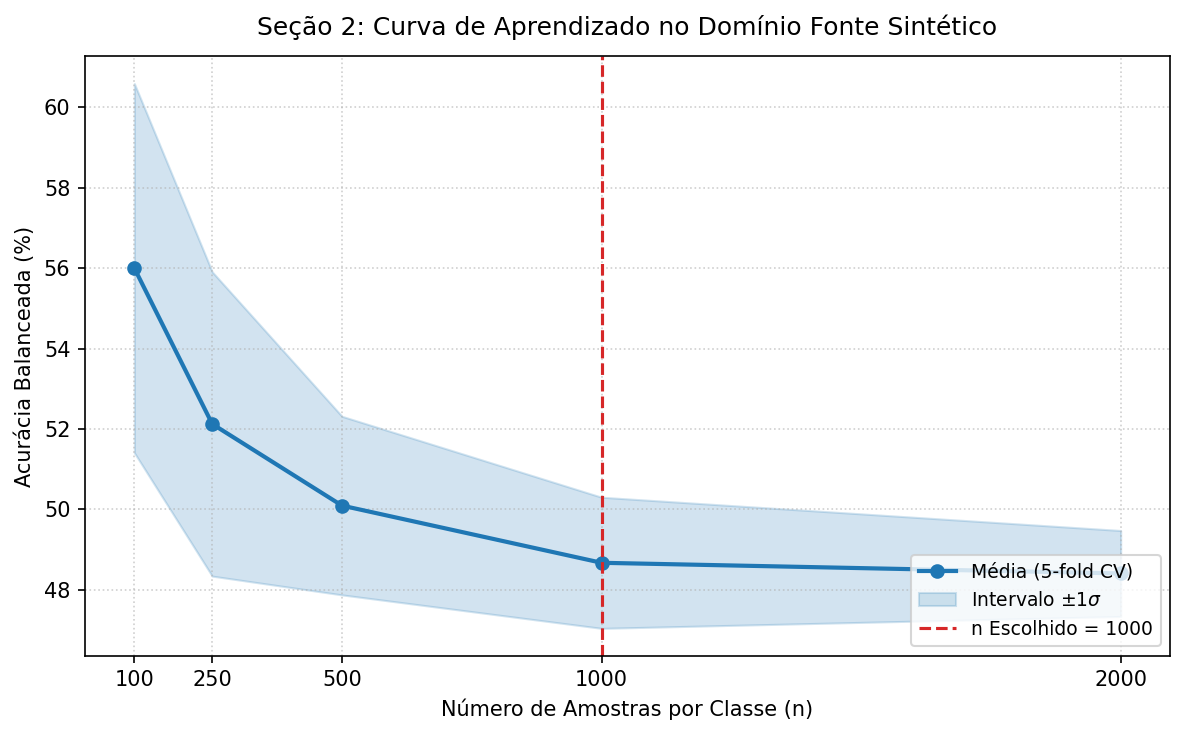


Valor de n selecionado para a dissertação: 1000 amostras por classe.


In [ ]:
# ==============================================================================
# Seção 1: Congelamento Anti-Leakage (Fase A)
# Seção 2: Curva de Aprendizado (Metodologia 3.2.1)
# ==============================================================================
import os
import sys
from pathlib import Path
import importlib
import importlib.util
import matplotlib.pyplot as plt

# 1. Garantir que os caminhos raiz e src estejam no sys.path
BASE_DIR = Path('/content/drive/MyDrive/FEM_DISSERTACAO_LUMO/dissertacao-shm-transfer-learning')
SRC_DIR = BASE_DIR / 'src'
LC_FILE = SRC_DIR / 'learning_curve.py'

for p in [str(BASE_DIR), str(SRC_DIR)]:
    if p not in sys.path:
        sys.path.insert(0, p)

# 2. Carregar o módulo learning_curve de forma robusta
try:
    from src import learning_curve
    importlib.reload(learning_curve)
except ModuleNotFoundError:
    spec = importlib.util.spec_from_file_location("learning_curve", str(LC_FILE))
    learning_curve = importlib.util.module_from_spec(spec)
    sys.modules["learning_curve"] = learning_curve
    sys.modules["src.learning_curve"] = learning_curve
    spec.loader.exec_module(learning_curve)

# 3. Executar Seção 1 (Isolamento de Calibração e Limiar - Fase A)
df_calib, df_limiar = learning_curve.isolar_dados_fase_a(df_real)

# Blindagem anti-leakage: remove o DataFrame geral com teste da memória
if 'df_real' in locals() or 'df_real' in globals():
    del df_real

# 4. Executar Seção 2 (Curva de Aprendizado no Domínio Fonte Sintético)
cols_feat = [c for c in df_sint.columns if c.startswith("feat_")]

res_curva = learning_curve.avaliar_curva_aprendizado(
    df_sint=df_sint,
    cols_feat=cols_feat,
    random_state=42
)

# 5. Exibir Gráfico da Curva de Aprendizado
fig_curva = learning_curve.plotar_curva_aprendizado(res_curva)
plt.show()

print(f"\nValor de n selecionado para a dissertação: {res_curva['n_escolhido']} amostras por classe.")

# Seções 3 a 6: Alinhamento, Otimização e Congelamento (Fase A)

In [2]:
# ==============================================================================
# Seções 3 a 6: Alinhamento, Otimização com Checkpoints e Limiares (Fase A)
# ==============================================================================
import os
import sys
from pathlib import Path
import importlib
import importlib.util
import numpy as np
import pandas as pd
import yaml

# 1. Configurar caminhos e montagem do Drive
if not os.path.exists('/content/drive/MyDrive'):
    from google.colab import drive
    drive.mount('/content/drive')

BASE_DIR = Path('/content/drive/MyDrive/FEM_DISSERTACAO_LUMO/dissertacao-shm-transfer-learning')
SRC_DIR = BASE_DIR / 'src'
MODELS_FILE = SRC_DIR / 'phase_a_models.py'
LC_FILE = SRC_DIR / 'learning_curve.py'

for p in [str(BASE_DIR), str(SRC_DIR)]:
    if p not in sys.path:
        sys.path.insert(0, p)

try:
    from src import phase_a_models, learning_curve
    importlib.reload(phase_a_models)
    importlib.reload(learning_curve)
except ModuleNotFoundError:
    spec_lc = importlib.util.spec_from_file_location("learning_curve", str(LC_FILE))
    learning_curve = importlib.util.module_from_spec(spec_lc)
    sys.modules["learning_curve"] = learning_curve
    sys.modules["src.learning_curve"] = learning_curve
    spec_lc.loader.exec_module(learning_curve)

    spec_m = importlib.util.spec_from_file_location("phase_a_models", str(MODELS_FILE))
    phase_a_models = importlib.util.module_from_spec(spec_m)
    sys.modules["phase_a_models"] = phase_a_models
    sys.modules["src.phase_a_models"] = phase_a_models
    spec_m.loader.exec_module(phase_a_models)

# 2. Carregar dados se necessário
with open(BASE_DIR / 'configs' / 'config_data.yaml', 'r', encoding='utf-8') as f:
    cfg_data = yaml.safe_load(f)

if 'df_sint' not in locals() or 'df_sint' not in globals():
    path_sint = BASE_DIR / cfg_data['dataset_paths']['sintetico_abaqus']
    print(f"Carregando sintético de: {path_sint.name}...")
    df_sint = pd.read_parquet(path_sint)

if 'df_calib' not in locals() or 'df_limiar' not in locals():
    path_real = BASE_DIR / cfg_data['dataset_paths']['real_lumo']
    print(f"Carregando partições da Fase A de: {path_real.name}...")
    df_real_temp = pd.read_parquet(path_real)
    df_calib, df_limiar = learning_curve.isolar_dados_fase_a(df_real_temp)
    del df_real_temp

# 3. Extração do subconjunto S com n = 1000 por classe (escolha da Seção 2)
N_ESCOLHIDO = 1000
cols_feat = [c for c in df_sint.columns if c.startswith("feat_")]

print(f"\nExtraindo subconjunto S (n = {N_ESCOLHIDO} por classe)...")
X_s, y_s, groups_s = phase_a_models.extrair_conjunto_trabalho_sintetico(df_sint, N_ESCOLHIDO, cols_feat)
X_c = df_calib[cols_feat].values.astype(np.float64)
X_l = df_limiar[cols_feat].values.astype(np.float64)

# 4. Seção 3: Padronização e Alinhamento
print("\n>>> [Seção 3] Computando No-DA, NCA e CORAL...")
dados_alin = phase_a_models.computar_alinhamentos(X_s, y_s, X_c, X_l)
print(" -> [OK] Transformações concluídas.")

# 5. Seção 4: Otimização SVM com Checkpoints e Barra de Status
chk_dir = str(BASE_DIR / 'artefatos_congelados' / 'checkpoints')
modelos_svm = {}
info_grade = {}

for espaco in ["No-DA", "NCA", "CORAL"]:
    clf, info = phase_a_models.otimizar_svm(
        dados_alin[espaco]["Xs"],
        y_s,
        groups_s,
        nome_espaco=espaco,
        checkpoint_dir=chk_dir,
        random_state=42
    )
    modelos_svm[espaco] = clf
    info_grade[espaco] = info
    print(f" [VENCEDOR {espaco}] C={info['params']['C']}, gamma={info['params']['gamma']} (Acurácia CV: {info['melhor_score']*100:.2f}%)")

# 6. Seção 5: Detector Target-Only (PCA + MSD)
print("\n>>> [Seção 5] Ajustando Detector Target-Only (PCA + Mahalanobis MSD)...")
mod_to = phase_a_models.ajustar_target_only(dados_alin["NCA"]["Xc"])
print(f" -> Componentes PCA retidos (>= 95% var): {mod_to['n_componentes']}")
print(f" -> Condicionamento da covariância: {mod_to['cond_num']:.2e}")

# 7. Seção 6: Limiares T e Congelamento Formal
pasta_congelada = str(BASE_DIR / 'artefatos_congelados')
meta_fase_a = {
    "n_por_classe": N_ESCOLHIDO,
    "seed": 42,
    "hiperparametros": info_grade,
    "target_only_componentes": mod_to['n_componentes']
}

artefatos_congelados = phase_a_models.computar_limiares_congelar(
    modelos_svm=modelos_svm,
    modelo_target_only=mod_to,
    dados_alinhados=dados_alin,
    subconjunto_meta=meta_fase_a,
    diretorio_saida=pasta_congelada
)

print("\n" + "=" * 75)
print("TABELA DE LIMIARES ESTATÍSTICOS T (Percentil 99 no Limiar)")
print("=" * 75)
display(pd.DataFrame(artefatos_congelados["limiares"]).T)

Carregando sintético de: dataset_sintetico_abaqus.parquet...
Carregando partições da Fase A de: dataset_real_lumo.parquet...
[FASE A: ANTI-LEAKAGE] Calibração (C) e Limiar (L) isolados com sucesso.
 -> Calibração: 1959 blocos (14 dias)
 -> Limiar:      730 blocos (7 dias)
 -> O conjunto de Teste permanece inacessível até a Fase B (Seção 7).

Extraindo subconjunto S (n = 1000 por classe)...

>>> [Seção 3] Computando No-DA, NCA e CORAL...
 -> [OK] Transformações concluídas.

[Ajuste SVM: No-DA] Avaliando 9 combinações de hiperparâmetros (5-fold CV agrupado)...


Grade No-DA:   0%|          | 0/9 [00:00<?, ?comb/s]

KeyboardInterrupt: 

In [3]:
%cd /content/drive/MyDrive/FEM_DISSERTACAO_LUMO/dissertacao-shm-transfer-learning
!git add src/ notebooks/ configs/
!git commit -m "feat: checkpoints e otimizacao paralela para phase_a"
!git push origin main

/content/drive/MyDrive/FEM_DISSERTACAO_LUMO/dissertacao-shm-transfer-learning
Author identity unknown

*** Please tell me who you are.

Run

  git config --global user.email "you@example.com"
  git config --global user.name "Your Name"

to set your account's default identity.
Omit --global to set the identity only in this repository.

fatal: unable to auto-detect email address (got 'root@31d9f69e9130.(none)')
Everything up-to-date
